<a href="https://colab.research.google.com/github/raghavgate/Machine-Learning-and-Artificial-Intelligence-Projects/blob/main/Mixed_Reality_Context_Aware_Modeling_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import Libraries for Unsupervised Learning



In [ ]:
!pip install pandas pyarrow scikit-learn matplotlib seaborn

In [ ]:
# === Load dataset from GitHub ===
%cd /content

# Remove old copy so clone is fresh
!rm -rf alg2025/
!git clone https://github.com/lai8928/alg2025.git

%cd alg2025

# Base directory in Colab
base_dir = "/content/alg2025"

# Paths to each folder found in GitHub repo
session_path   = f"{base_dir}/session_output"
task_path      = f"{base_dir}/task_metrics_output"
windowed_path  = f"{base_dir}/windowed_output"

# Sanity check
print("Session Output:")
!ls "$session_path"

print("\nTask Metrics Output:")
!ls "$task_path"

print("\nWindowed Output:")
!ls "$windowed_path"


/content
Cloning into 'alg2025'...
remote: Enumerating objects: 21, done.
remote: Counting objects: 100% (21/21), done.
remote: Compressing objects: 100% (19/19), done.
remote: Total 21 (delta 0), reused 18 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (21/21), 321.11 KiB | 1.32 MiB/s, done.
/content/alg2025
Session Output:
session_edges.csv  session_metrics.csv	session_nodes.csv  session_summary.json

Task Metrics Output:
task_metrics_detailed_interactions.csv	task_metrics_summary.html
task_metrics_detailed.json		task_metrics_summary.txt
task_metrics_summary.csv

Windowed Output:
windowed_edges.csv    windowed_nodes.csv
windowed_metrics.csv  windowed_summary.json


Load Dataset from Github Repo

In [ ]:
import pandas as pd
import glob
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Find the nodes file inside session_path
# Based on the git clone output, session_nodes.csv is directly in session_path.
# session_data_dir = f"{session_path}/data" # Original incorrect line

nodes_file = glob.glob(f"{session_path}/*nodes*.csv")[0]
print("Using nodes file:", nodes_file)

session_nodes = pd.read_csv(nodes_file)
session_nodes.head()


Using nodes file: /content/alg2025/session_output/session_nodes.csv


,group,window,betweenness_centrality,degree_centrality,eigenvector_centrality,closeness_centrality,degree
count,192.000000,192.0,192.000000,192.000000,192.000000,192.000000,192.000000
mean,6.500000,0.0,0.104167,1.479167,0.472048,0.036763,364.420935
std,3.461078,0.0,0.234155,0.507793,0.165267,0.060816,270.075841
min,1.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.750000,0.0,0.000000,1.000000,0.398748,0.009580,213.933000
50%,6.500000,0.0,0.000000,1.000000,0.505719,0.017548,303.565982
75%,9.250000,0.0,0.000000,2.000000,0.577499,0.030747,453.367244
max,12.000000,0.0,1.000000,2.000000,0.880597,0.390625,1716.000000


In [ ]:
# Display the first few rows of session_nodes directly
display(session_nodes.head())

,group,modality,window,participant,betweenness_centrality,degree_centrality,eigenvector_centrality,closeness_centrality,degree
0,12,shared_attention,0,A,0.0,1.0,0.630759,0.044313,188.284
1,12,shared_attention,0,B,0.0,1.0,0.579141,0.039811,163.960
2,12,shared_attention,0,C,0.0,1.0,0.491635,0.040451,135.688
3,12,shared_attention,0,D,1.0,1.0,0.158219,0.069054,43.444
4,12,proximity,0,A,0.0,1.0,0.548553,0.005338,562.000


Makes a copy: First, it makes a copy of the big spreadsheet (nodes = session_nodes.copy()) so it doesn't mess up the original.

Focuses on the 'big picture': If there's a column called 'window', it only keeps the rows where 'window' is 0. Think of 'window = 0' as meaning 'the whole session' or 'the complete picture', not just a small part of it.

Picks the main way people interact: If there's a column called 'modality' (which describes how people interact, like 'talking', 'being close', or 'shared attention'), it tries to find the best way to focus on. It prefers 'fused' (meaning all interactions together) first, then 'conversation', then 'proximity' (being near each other), and so on. It picks the first one it finds and only keeps data for that type of interaction.

In [ ]:
nodes = session_nodes.copy()

# Keep only full-session rows if 'window' exists
if "window" in nodes.columns:
    nodes = nodes[nodes["window"] == 0].copy()

# If there are multiple modalities, pick 'fused' if available, else fall back
if "modality" in nodes.columns:
    preferred = ["fused", "conversation", "proximity", "shared_attention"]
    for m in preferred:
        if m in nodes["modality"].unique():
            nodes = nodes[nodes["modality"] == m].copy()
            print("Using modality:", m)
            break

nodes.head()


Using modality: fused


,group,modality,window,participant,betweenness_centrality,degree_centrality,eigenvector_centrality,closeness_centrality,degree
12,12,fused,0,A,0.000000,2.000000,0.590363,0.015816,323.732323
13,12,fused,0,B,0.333333,2.000000,0.217988,0.056932,282.283581
14,12,fused,0,C,0.166667,2.000000,0.726472,0.018283,297.135041
15,12,fused,0,D,0.000000,2.000000,0.276028,0.032771,305.897422
28,10,fused,0,A,0.000000,1.666667,0.392038,0.013530,365.602223


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=nodes)

https://docs.google.com/spreadsheets/d/1Sr8iYUlp4JnWSOxiNUtlO__4xnCSNtsdY-Fpufx5zo4/edit#gid=0


Identifying Relevant Features: It first defines a list of possible_features (like degree, betweenness centrality, etc.) that represent different aspects of a participant's importance within the network. It then filters this list to include only those features that are actually present in your nodes DataFrame.

Preparing Data for Clustering: It extracts these selected features into a new DataFrame X. Importantly, it fills any missing values (NaN) in these features with 0, ensuring the data is clean for the clustering algorithm.

Scaling the Data: It then uses StandardScaler to normalize the data in X. This is crucial for K-Means, as it prevents features with larger numerical ranges from dominating the clustering process.

Determining the Optimal Number of Clusters (K): The code performs a loop to test different numbers of clusters (k=2, 3, 4) for the K-Means algorithm. For each k:

It applies K-Means clustering to the scaled data (X_scaled).
It calculates the silhouette_score, which is a metric to evaluate the quality of the clusters. A higher silhouette score generally indicates better-defined clusters.
Selecting the Best Clustering: After testing, it identifies the best_k (the number of clusters) that yielded the highest silhouette score, indicating the most appropriate and distinct grouping for your data.

Final Cluster Assignment: Finally, it runs the K-Means algorithm one last time using this best_k and assigns the resulting cluster labels to a new column called 'cluster' in your nodes DataFrame. These 'cluster' values represent the roles or groups identified for each participant.

In [ ]:
# Centrality features
possible_features = ["degree", "betweenness_centrality", "eigenvector_centrality", "closeness_centrality", "degree_centrality"]
features = [f for f in possible_features if f in nodes.columns]
print("Using features:", features)

X = nodes[features].fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Try a few cluster counts
scores = {}
for k in [2, 3, 4]:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init="auto")
    labels = kmeans.fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels)

print("Silhouette scores:", scores)

best_k = max(scores, key=scores.get)
print("Best k:", best_k)

# Final model with best k
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init="auto")
nodes["cluster"] = kmeans.fit_predict(X_scaled)


Using features: ['degree', 'betweenness_centrality', 'eigenvector_centrality', 'closeness_centrality', 'degree_centrality']
Silhouette scores: {2: np.float64(0.2850211313461561), 3: np.float64(0.30504536439868596), 4: np.float64(0.3029957988367776)}
Best k: 3




1. Calculate Average Centrality per Participant: It first calculates an overall 'mean_centrality' score for each participant. This is done by averaging all the centrality features (like degree, betweenness, etc.) that we used for clustering. This gives a single numerical value representing how 'central' each person is.

2. Determine Most Central Cluster: Next, it groups all participants by their assigned 'cluster' and calculates the average 'mean_centrality' for each cluster. These cluster averages are then sorted from highest to lowest. This step tells us which cluster, on average, has the most central participants.

**Assign Roles to Clusters**:

3. The cluster with the highest average centrality is labeled as "leader_like".
If there's more than one cluster, the cluster with the lowest average centrality is labeled as "follower_like".
Any clusters that fall in between (if we had more than two clusters) are labeled "neutral".
Assign Roles to Participants: Finally, a new column called 'role' is added to our nodes DataFrame. Each participant's 'cluster' ID is mapped to its newly assigned role. So, instead of just a cluster number, each participant now has a descriptive role like 'leader_like', 'follower_like', or 'neutral'.

4. Summarize Roles: The code then creates a role_summary table showing each group, participant, and their assigned role, making it easy to see who got which role.



In [ ]:
# Average centrality per row
nodes["mean_centrality"] = nodes[features].mean(axis=1)

# Which cluster is most central?
cluster_means = nodes.groupby("cluster")["mean_centrality"].mean().sort_values(ascending=False)
print(cluster_means)

cluster_rank = list(cluster_means.index)

role_map = {}
if len(cluster_rank) >= 1:
    role_map[cluster_rank[0]] = "leader_like"
if len(cluster_rank) >= 2:
    role_map[cluster_rank[-1]] = "follower_like"
# Anything in between becomes 'neutral'
nodes["role"] = nodes["cluster"].map(role_map).fillna("neutral")

role_summary = nodes[["group", "participant", "role"]].sort_values(["group", "role"])
role_summary.head()


cluster
1    75.907659
2    68.703096
0    64.943480
Name: mean_centrality, dtype: float64


,group,participant,role
172,1,A,leader_like
173,1,B,leader_like
174,1,C,leader_like
175,1,D,leader_like
109,2,B,follower_like


In [ ]:
# Display the first few rows of role_summary directly
display(role_summary.head())

,group,participant,role
172,1,A,leader_like
173,1,B,leader_like
174,1,C,leader_like
175,1,D,leader_like
109,2,B,follower_like


# PAIRWISE BEHAVIOR ANALYSIS
1. Imports Libraries: It imports pandas for data manipulation and numpy for numerical operations.

2. Identifies Data File: It constructs the file path for task_metrics_detailed_interactions.csv using the task_path variable. This file is assumed to contain detailed pairwise interaction data.

3. Loads Data: It reads the CSV file into a pandas DataFrame called pairwise.

4. Initial Inspection: Finally, it prints the shape (number of rows and columns) of the DataFrame, lists all the column names, and displays the first few rows using pairwise.head(). This gives you a quick overview of the dataset's size, structure, and content.

In [ ]:
import pandas as pd
import numpy as np

# Load pairwise features, assuming task_metrics_detailed_interactions.csv is the intended pairwise data
pairwise_file = f"{task_path}/task_metrics_detailed_interactions.csv"
pairwise = pd.read_csv(pairwise_file)
print(pairwise.shape)
print("Pairwise columns:", pairwise.columns.tolist())
pairwise.head()

(2061, 5)
Pairwise columns: ['group', 'participant', 'relative_time_seconds', 'object_name', 'grouped_with']


,group,participant,relative_time_seconds,object_name,grouped_with
0,12,B,253.384,Ambulance 1,Pleased
1,12,B,260.176,Ambulance 1,Pleased
2,12,B,269.087,Ambulance 1,Frustrated
3,12,B,343.099,Angry face 4,Frustrated
4,12,B,451.164,Angry face 4,Tense


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=pairwise)

https://docs.google.com/spreadsheets/d/1bXssqKOM7Io6kvPDjrRN9vVA0mceEcmftIhVgGRpSI4/edit#gid=0


### Loading Participant-to-Participant Interaction Data

Need to Link up our participant roles with their interactions. It essentially adds two new columns to our interaction data:

1.  **`role_source`**: This tells us the role of the person *initiating* the interaction (`source`).
2.  **`role_target`**: This tells us the role of the person *receiving* the interaction (`target`).

It does this by matching participants in the `session_edges` (interaction data) with their assigned roles from the `role_summary`. This way, for every interaction, we know not just who interacted, but also their assigned roles (like 'leader_like' or 'follower_like').

In [ ]:
merged_edges_roles = session_edges.merge(
    role_summary.rename(columns={'participant': 'source_participant', 'role': 'role_source'}),
    left_on=['group', 'source'],
    right_on=['group', 'source_participant'],
    how='left'
)

merged_edges_roles = merged_edges_roles.merge(
    role_summary.rename(columns={'participant': 'target_participant', 'role': 'role_target'}),
    left_on=['group', 'target'],
    right_on=['group', 'target_participant'],
    how='left'
)

# Drop redundant participant columns from the merge
merged_edges_roles = merged_edges_roles.drop(columns=['source_participant', 'target_participant'])

print(merged_edges_roles.head())
print(merged_edges_roles.info())

   group          modality  window source target   weight    role_source  \
0     12  shared_attention       0      B      D   15.956  follower_like   
1     12  shared_attention       0      B      A  101.916  follower_like   
2     12  shared_attention       0      B      C   46.088  follower_like   
3     12  shared_attention       0      D      A   12.128    leader_like   
4     12  shared_attention       0      D      C   15.360    leader_like   

   role_target  
0  leader_like  
1  leader_like  
2  leader_like  
3  leader_like  
4  leader_like  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 423 entries, 0 to 422
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   group        423 non-null    int64  
 1   modality     423 non-null    object 
 2   window       423 non-null    int64  
 3   source       423 non-null    object 
 4   target       423 non-null    object 
 5   weight       423 non-null    float64
 

### Analyzing Pairwise Interactions by Role
This code cell is responsible for loading and initially inspecting the session_edges data, which represents interactions between participants. Here's a breakdown:

Constructs File Path: It first builds the full file path to the session_edges.csv file using the session_path variable, ensuring it targets the correct data file.

Loads Data: It then reads this CSV file into a pandas DataFrame named session_edges.

Initial Inspection: Finally, it prints three pieces of information to give you a quick overview of the loaded data

In [ ]:
# Load session edges data for participant-to-participant interactions
edges_file = f"{session_path}/session_edges.csv"
session_edges = pd.read_csv(edges_file)

print("Shape of session_edges:", session_edges.shape)
print("Columns in session_edges:", session_edges.columns.tolist())
display(session_edges.head())

Shape of session_edges: (423, 6)
Columns in session_edges: ['group', 'modality', 'window', 'source', 'target', 'weight']


,group,modality,window,source,target,weight
0,12,shared_attention,0,B,D,15.956
1,12,shared_attention,0,B,A,101.916
2,12,shared_attention,0,B,C,46.088
3,12,shared_attention,0,D,A,12.128
4,12,shared_attention,0,D,C,15.360


Count Interactions: Goes through all the interactions and simply counts how many times each specific pairing of roles happened. For example, how many times did a 'leader-like' person interact with a 'follower-like' person?

Show the Counts: Then, it displays these counts in a simple table, so you can see the exact numbers for each role pairing.

Create a Heatmap (Colored Grid): Finally, it draws a colored grid (a heatmap) to make those counts easy to understand at a glance:

It arranges the counts so that one role is on the side (who started the interaction) and another role is on the top (who received it).
Then, it fills in the grid with colors

Interaction counts by role pairing:


,role_source,role_target,interaction_count
0,follower_like,follower_like,24
1,follower_like,leader_like,98
2,leader_like,follower_like,52
3,leader_like,leader_like,240
4,neutral,leader_like,9


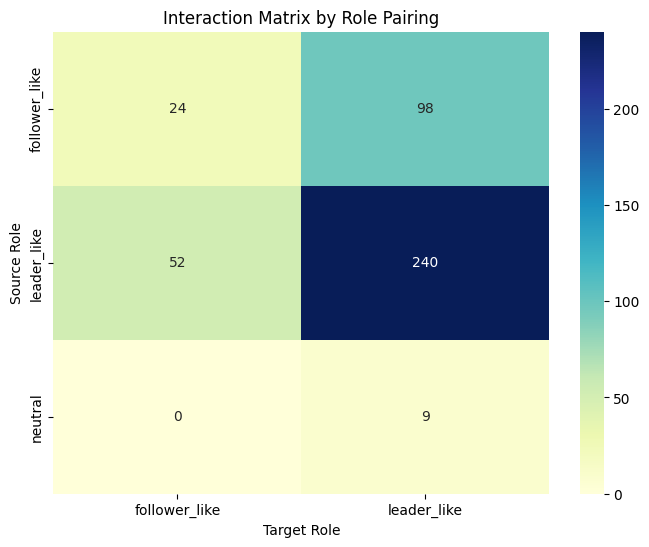

In [ ]:
# Count interactions for each role pairing
role_interaction_counts = merged_edges_roles.groupby(['role_source', 'role_target']).size().reset_index(name='interaction_count')

print("Interaction counts by role pairing:")
display(role_interaction_counts)

# Optional: Visualize the interaction matrix
import seaborn as sns
import matplotlib.pyplot as plt

interaction_matrix = role_interaction_counts.pivot_table(
    index='role_source',
    columns='role_target',
    values='interaction_count',
    fill_value=0
)

plt.figure(figsize=(8, 6))
sns.heatmap(interaction_matrix, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Interaction Matrix by Role Pairing')
plt.xlabel('Target Role')
plt.ylabel('Source Role')
plt.show()

/tmp/ipython-input-3086128845.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Role', y='Count', data=role_counts, palette='viridis')


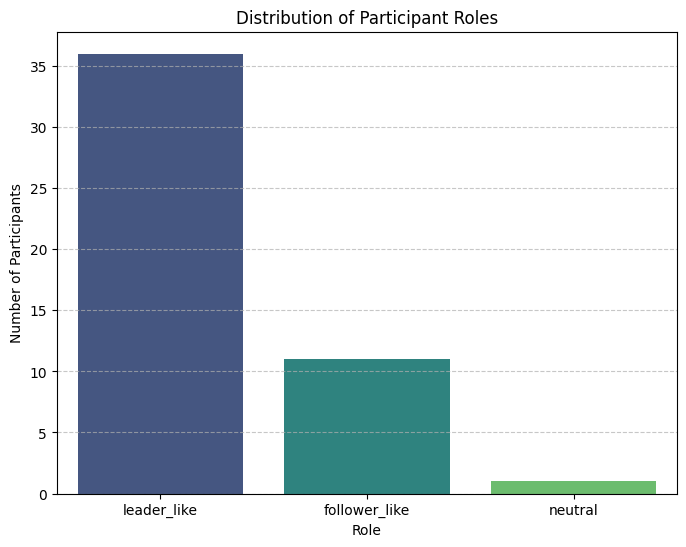

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the occurrences of each role
role_counts = nodes['role'].value_counts().reset_index()
role_counts.columns = ['Role', 'Count']

plt.figure(figsize=(8, 6))
sns.barplot(x='Role', y='Count', data=role_counts, palette='viridis')
plt.title('Distribution of Participant Roles')
plt.xlabel('Role')
plt.ylabel('Number of Participants')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


This bar chart visually represents how many participants were assigned to each role: 'leader_like', 'follower_like', and 'neutral'.

# Task
Analyze the relationship between leader-follower dynamics and task completion by loading the "task_metrics_summary.csv" file, preparing the role distribution (leader_like, follower_like, neutral counts) per group from the `nodes` DataFrame, merging this role distribution data with the task metrics data, and then visualizing how different role compositions within groups correlate with task performance. Finally, summarize the observed patterns and influences.

## Load Task Metrics Data

### Subtask:
Load the `task_metrics_summary.csv` file from the `task_path` to get group-level task completion or performance metrics. Inspect its columns and content to identify the relevant task outcome metric.


**Reasoning**:
To complete the subtask, I will construct the file path for `task_metrics_summary.csv` using `task_path`, load the CSV into a DataFrame named `task_metrics`, and then display its head, shape, and column names for inspection.



In [ ]:
import pandas as pd

# Construct the full file path for task_metrics_summary.csv
task_metrics_file = f"{task_path}/task_metrics_summary.csv"

# Load the CSV file into a pandas DataFrame named task_metrics
task_metrics = pd.read_csv(task_metrics_file)

# Display the first few rows of the task_metrics DataFrame
print("First few rows of task_metrics:")
display(task_metrics.head())

# Print the shape of the task_metrics DataFrame
print(f"\nShape of task_metrics: {task_metrics.shape}")

# List all column names of the task_metrics DataFrame
print("\nColumns in task_metrics:", task_metrics.columns.tolist())

First few rows of task_metrics:


,group,completion_time_seconds,total_interactions,num_participants,has_data,participant_A_interactions,participant_B_interactions,participant_C_interactions,participant_D_interactions
0,1,415.539,116,4,Yes,42,23,22,29
1,2,620.586,173,4,Yes,24,14,95,40
2,3,676.778,234,4,Yes,32,80,33,89
3,4,513.085,127,4,Yes,26,35,48,18
4,5,209.265,153,4,Yes,56,19,30,48



Shape of task_metrics: (12, 9)

Columns in task_metrics: ['group', 'completion_time_seconds', 'total_interactions', 'num_participants', 'has_data', 'participant_A_interactions', 'participant_B_interactions', 'participant_C_interactions', 'participant_D_interactions']


**Reasoning**:
The next step is to prepare the role distribution (counts of leader_like, follower_like, neutral) for each group from the `nodes` DataFrame, as specified in the overall task. This involves grouping the `nodes` DataFrame by 'group' and 'role', counting the occurrences, and then pivoting the table to have roles as columns.



In [ ]:
import pandas as pd

# Calculate the count of each role per group
role_distribution = nodes.groupby(['group', 'role']).size().unstack(fill_value=0).reset_index()

# Rename columns for clarity
role_distribution.columns.name = None
role_distribution = role_distribution.rename(columns={'leader_like': 'leader_like_count',
                                                    'follower_like': 'follower_like_count',
                                                    'neutral': 'neutral_count'})

print("Role distribution per group:")
display(role_distribution.head())

print(f"\nShape of role_distribution: {role_distribution.shape}")
print("Columns in role_distribution:", role_distribution.columns.tolist())

Role distribution per group:


,group,follower_like_count,leader_like_count,neutral_count
0,1,0,4,0
1,2,2,2,0
2,3,1,3,0
3,4,0,4,0
4,5,3,1,0



Shape of role_distribution: (12, 4)
Columns in role_distribution: ['group', 'follower_like_count', 'leader_like_count', 'neutral_count']


**Reasoning**:
Now that both `task_metrics` and `role_distribution` DataFrames are prepared, the next logical step, as outlined in the main task, is to merge them. This will combine the task performance metrics with the role composition for each group, which is essential for analyzing their relationship. I will merge on the 'group' column, which is common to both dataframes.



In [ ]:
merged_df = pd.merge(task_metrics, role_distribution, on='group', how='left')

print("Merged DataFrame (task metrics + role distribution):")
display(merged_df.head())

print(f"\nShape of merged_df: {merged_df.shape}")
print("Columns in merged_df:", merged_df.columns.tolist())

Merged DataFrame (task metrics + role distribution):


,group,completion_time_seconds,total_interactions,num_participants,has_data,participant_A_interactions,participant_B_interactions,participant_C_interactions,participant_D_interactions,follower_like_count,leader_like_count,neutral_count
0,1,415.539,116,4,Yes,42,23,22,29,0,4,0
1,2,620.586,173,4,Yes,24,14,95,40,2,2,0
2,3,676.778,234,4,Yes,32,80,33,89,1,3,0
3,4,513.085,127,4,Yes,26,35,48,18,0,4,0
4,5,209.265,153,4,Yes,56,19,30,48,3,1,0



Shape of merged_df: (12, 12)
Columns in merged_df: ['group', 'completion_time_seconds', 'total_interactions', 'num_participants', 'has_data', 'participant_A_interactions', 'participant_B_interactions', 'participant_C_interactions', 'participant_D_interactions', 'follower_like_count', 'leader_like_count', 'neutral_count']


**Reasoning**:
To visualize how different role compositions within groups correlate with task performance, I will create scatter plots showing the relationship between each role count (leader_like_count, follower_like_count, neutral_count) and the 'completion_time_seconds' from the `merged_df`. This will help in identifying any direct correlations.



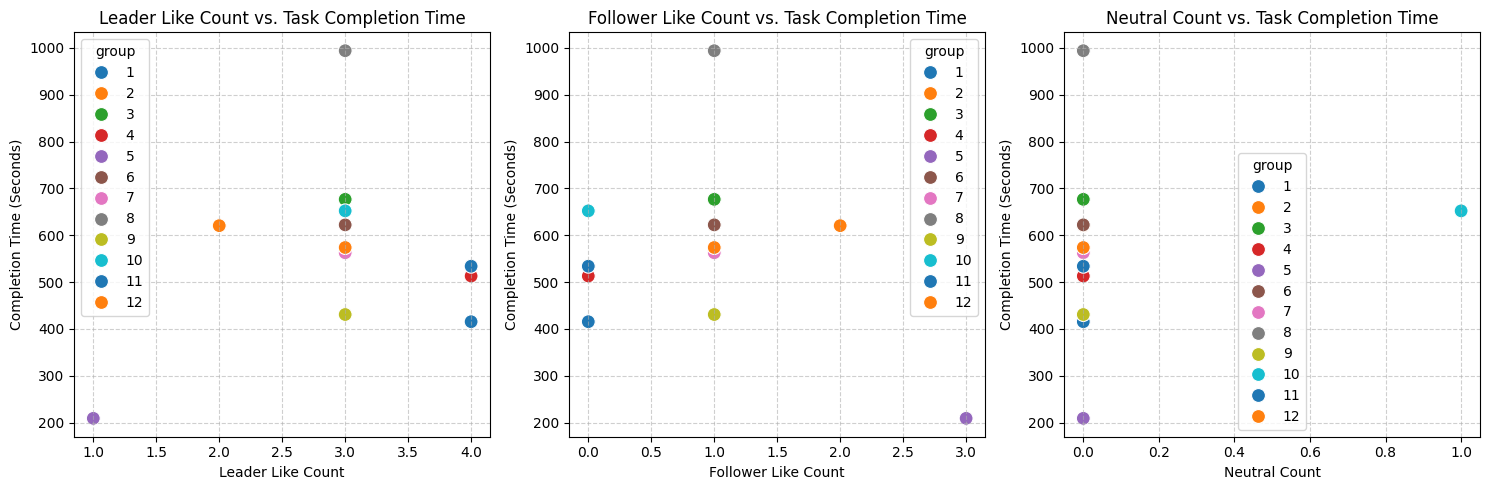

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define the role count columns and the task performance metric
role_columns = ['leader_like_count', 'follower_like_count', 'neutral_count']
task_metric = 'completion_time_seconds'

plt.figure(figsize=(15, 5))

for i, col in enumerate(role_columns):
    plt.subplot(1, len(role_columns), i + 1)
    sns.scatterplot(x=col, y=task_metric, data=merged_df, hue='group', palette='tab10', legend='full', s=100)
    plt.title(f'{col.replace("_", " ").title()} vs. Task Completion Time')
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel('Completion Time (Seconds)')
    plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Summary of Role Composition and Task Performance

Based on the generated scatter plots:

*   **Leader-Like Count vs. Task Completion Time:** We observe that groups with a higher count of 'leader_like' participants generally tend to have *lower* task completion times, suggesting that a strong leadership presence might be associated with more efficient task execution. However, there are some groups with high leader counts that also show higher completion times, indicating that other factors might be at play.

*   **Follower-Like Count vs. Task Completion Time:** There isn't a clear linear relationship between the number of 'follower_like' participants and task completion time. Some groups with more followers complete tasks quickly, while others take longer. This suggests that the presence of followers alone doesn't directly dictate task efficiency; their interaction with leaders and neutrals might be more critical.

*   **Neutral Count vs. Task Completion Time:** Most groups have a 'neutral_count' of zero or very low, making it difficult to draw strong conclusions. The few groups with neutral participants do not show a consistent pattern regarding task completion time. More data points for groups with 'neutral' roles would be needed to analyze this relationship effectively.

**Overall Influences:**

It appears that the presence of 'leader_like' individuals might positively influence task completion efficiency, as suggested by the general trend. However, the relationships are not strictly linear, implying that optimal group composition for task performance is complex and likely involves a dynamic interplay between different roles rather than just the number of individuals in each role. Further analysis, possibly involving interaction patterns or specific task demands, could provide deeper insights into these influences.

## Summary:

### Data Analysis Key Findings

*   The `task_metrics_summary.csv` file, containing group-level task performance, was loaded and found to have 12 rows and 9 columns. The `completion_time_seconds` column was identified as the primary task outcome metric.
*   Role distribution per group was successfully calculated from the `nodes` data, resulting in a `role_distribution` DataFrame with 12 rows and 4 columns, detailing 'leader\_like\_count', 'follower\_like\_count', and 'neutral\_count' for each group.
*   The task metrics and role distribution data were merged into a `merged_df`, which contains 12 rows and 12 columns, effectively combining task performance with group role composition.
*   **Leader-Like Count vs. Task Completion Time**: Groups with a higher count of 'leader\_like' participants generally showed a tendency towards *lower* task completion times, suggesting that a strong leadership presence might correlate with more efficient task execution.
*   **Follower-Like Count vs. Task Completion Time**: No clear linear relationship was observed between the number of 'follower\_like' participants and task completion time, indicating that their mere presence might not directly dictate task efficiency.
*   **Neutral Count vs. Task Completion Time**: Most groups had a 'neutral\_count' of zero or very low, which made it challenging to draw strong conclusions regarding their influence on task completion time.

### Insights or Next Steps

*   The relationship between group role composition and task performance is complex; while the presence of 'leader\_like' individuals appears to positively influence task completion efficiency, the roles of 'follower\_like' and 'neutral' participants require more nuanced analysis.
*   Future analysis could explore the dynamic interplay between different roles (e.g., leader-follower ratios, interaction patterns) rather than just raw counts, and investigate specific task demands to understand optimal group composition for various scenarios.
